<a href="https://colab.research.google.com/github/chilukuru-saikrishna/gambling-harm-early-detection/blob/main/gambling_harm_early_detection_bwin.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Early detection of gambling harm — bwin cross-game cohort (Braverman 2013)

**Goal:** using only a player's first 30 days of betting, predict whether they later triggered a responsible gambling (RG) intervention, and explain each prediction.

**Data:** Division on Addiction / bwin.party Transparency Project, Cohort 3 (RG cases vs matched controls). Cite: Braverman, J., LaPlante, D. A., Nelson, S. E., & Shaffer, H. J. (2013). *Using cross-game behavioral markers for early identification of high-risk Internet gamblers.* Psychology of Addictive Behaviors.

**Important:** until the real files are loaded, this notebook runs on a **simulated stand-in** with the same shape, so every cell can be tested. Results on simulated data mean nothing. Set `USE_REAL_DATA = True` once the files are in Drive and the column names in Cell 2 match the codebook.

**Steps:** 1 Setup · 2 Config · 3 Load data · 4 First-30-day window · 5 Features · 6 Rule-based baseline · 7 Models · 8 Evaluation · 9 SHAP explanations · 10 Summary

In [1]:
# Cell 1 — Setup
!pip install -q lightgbm shap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import shap
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, precision_score, recall_score, RocCurveDisplay

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print('Ready')

Ready


In [2]:
# Cell 2 — Config: edit this cell to match the codebook
USE_REAL_DATA = False   # switch to True once the real files are loaded

# File paths (after mounting Google Drive in Cell 3)
DAILY_FILE = '/content/drive/MyDrive/bwin/daily_aggregates.csv'   # one row per player per day per product
PLAYER_FILE = '/content/drive/MyDrive/bwin/players.csv'           # one row per player, with the RG flag

# Column names: rename these to whatever the codebook uses
COL = {
    'player':  'UserID',
    'date':    'Date',
    'product': 'ProductType',   # e.g. sports / casino / poker
    'stake':   'Stakes',
    'bets':    'Bets',
    'wins':    'Winnings',
}
PCOL = {
    'player':        'UserID',
    'rg_case':       'RGCase',          # 1 = triggered an RG intervention, 0 = control
    'first_deposit': 'FirstDepositDate',
}

WINDOW_DAYS = 30   # how many days after first deposit the model is allowed to see

In [3]:
# Cell 3 — Load data (real files, or a simulated stand-in for testing)

def simulate_standin(n_players=4000, seed=RANDOM_STATE):
    """Fake data with the same shape as the real cohort. FOR TESTING ONLY."""
    rng = np.random.default_rng(seed)
    products = ['sports', 'casino', 'poker']
    players, rows = [], []
    for pid in range(1, n_players + 1):
        case = int(pid <= n_players // 2)
        start = pd.Timestamp('2008-11-01') + pd.Timedelta(days=int(rng.integers(0, 365)))
        players.append((pid, case, start))
        risk = rng.normal(1.0 if case else 0.0, 1.0)          # overlapping groups, not perfectly separable
        active_p = np.clip(0.15 + 0.08 * risk, 0.03, 0.9)
        base = np.exp(rng.normal(2.5 + 0.35 * risk, 0.8))
        growth = 0.012 * risk + rng.normal(0, 0.01)
        n_prod = 1 + rng.binomial(2, np.clip(0.2 + 0.12 * risk, 0.02, 0.9))
        prods = rng.choice(products, size=n_prod, replace=False)
        for d in range(60):
            if rng.random() < active_p:
                for p in prods:
                    if rng.random() < 0.7:
                        stake = base * np.exp(growth * d) * rng.lognormal(0, 0.6 + 0.1 * max(risk, 0))
                        bets = max(1, int(rng.poisson(3 + max(risk, 0) * 2)))
                        wins = stake * rng.uniform(0.5, 1.05)
                        rows.append((pid, start + pd.Timedelta(days=d), p, stake, bets, wins))
    daily = pd.DataFrame(rows, columns=[COL['player'], COL['date'], COL['product'],
                                        COL['stake'], COL['bets'], COL['wins']])
    players = pd.DataFrame(players, columns=[PCOL['player'], PCOL['rg_case'], PCOL['first_deposit']])
    return daily, players

if USE_REAL_DATA:
    from google.colab import drive
    drive.mount('/content/drive')
    daily = pd.read_csv(DAILY_FILE)
    players = pd.read_csv(PLAYER_FILE)
    # If the files are SAS or SPSS instead of CSV, use pd.read_sas(...) or pd.read_spss(...)
else:
    daily, players = simulate_standin()
    print('⚠️  Using SIMULATED stand-in data. Results are for testing only.')

# Standardise column names so the rest of the notebook doesn't depend on the codebook
daily = daily.rename(columns={v: k for k, v in COL.items()})
players = players.rename(columns={v: k for k, v in PCOL.items()})
daily['date'] = pd.to_datetime(daily['date'])
players['first_deposit'] = pd.to_datetime(players['first_deposit'])

print(f'{len(daily):,} daily rows · {daily.player.nunique():,} players with activity')
print(players.rg_case.value_counts().rename({1: 'RG cases', 0: 'controls'}))
daily.head()

⚠️  Using SIMULATED stand-in data. Results are for testing only.
52,268 daily rows · 3,917 players with activity
rg_case
RG cases    2000
controls    2000
Name: count, dtype: int64


,player,date,product,stake,bets,wins
0,1,2008-12-06,poker,38.121667,4,30.688767
1,1,2008-12-16,poker,31.845466,4,19.241325
2,1,2008-12-17,poker,15.129395,5,14.261276
3,1,2008-12-21,poker,26.777957,6,15.075763
4,1,2008-12-30,poker,46.625596,3,30.528629


In [4]:
# Cell 4 — Keep only each player's first WINDOW_DAYS after first deposit
# This is what makes it EARLY detection, and it stops behaviour after the
# intervention from leaking into the model.
daily = daily.merge(players[['player', 'first_deposit']], on='player', how='inner')
daily['day'] = (daily['date'] - daily['first_deposit']).dt.days
window = daily[(daily['day'] >= 0) & (daily['day'] < WINDOW_DAYS)].copy()

print(f'Rows in first {WINDOW_DAYS} days: {len(window):,}')
print(f'Players with any activity in the window: {window.player.nunique():,} of {len(players):,}')

Rows in first 30 days: 26,018
Players with any activity in the window: 3,746 of 4,000


In [5]:
# Cell 5 — Behavioural features (one row per player)
# Each feature is a published early-risk marker; the comment maps it to the
# closest kind of factor in an operator's rule-based risk score.

per_day = window.groupby(['player', 'day']).agg(stake=('stake', 'sum'),
                                                bets=('bets', 'sum'),
                                                wins=('wins', 'sum')).reset_index()

def slope(g):
    # trend in daily stake over the window (escalation)
    if len(g) < 3:
        return 0.0
    return np.polyfit(g['day'], np.log1p(g['stake']), 1)[0]

f = per_day.groupby('player').agg(
    active_days=('day', 'nunique'),              # frequency of play
    total_stake=('stake', 'sum'),                # overall intensity (wager volume)
    total_bets=('bets', 'sum'),
    max_daily_stake=('stake', 'max'),            # peak intensity
    stake_sd=('stake', 'std'),                   # variability of play
    net_loss=('stake', 'sum'),
)
f['net_loss'] = f['total_stake'] - per_day.groupby('player')['wins'].sum()       # losses
f['stake_per_active_day'] = f['total_stake'] / f['active_days']
f['bets_per_active_day'] = f['total_bets'] / f['active_days']
f['stake_per_bet'] = f['total_stake'] / f['total_bets'].clip(lower=1)
f['stake_cv'] = (f['stake_sd'] / f['stake_per_active_day']).fillna(0)          # erratic staking
f['loss_ratio'] = (f['net_loss'] / f['total_stake']).clip(-1, 1)
f['stake_trend'] = per_day.groupby('player').apply(slope, include_groups=False) # escalation

# Second half of the window vs first half (another escalation signal)
half = WINDOW_DAYS // 2
first = per_day[per_day.day < half].groupby('player')['stake'].sum()
second = per_day[per_day.day >= half].groupby('player')['stake'].sum()
f['late_vs_early'] = np.log1p(second.reindex(f.index, fill_value=0)) - np.log1p(first.reindex(f.index, fill_value=0))

# Cross-game markers (the core idea in Braverman 2013)
f['n_products'] = window.groupby('player')['product'].nunique()
for p in sorted(window['product'].unique()):
    f[f'share_{p}'] = (window[window['product'] == p].groupby('player')['stake'].sum()
                       .reindex(f.index, fill_value=0) / f['total_stake'])

f = f.drop(columns=['stake_sd']).fillna(0)
data = players[['player', 'rg_case']].merge(f, left_on='player', right_index=True, how='left').fillna(0)
FEATURES = [c for c in data.columns if c not in ('player', 'rg_case')]
print(f'{len(FEATURES)} features:', FEATURES)
data.groupby('rg_case')[FEATURES].median().T.rename(columns={0: 'control median', 1: 'RG case median'})

16 features: ['active_days', 'total_stake', 'total_bets', 'max_daily_stake', 'net_loss', 'stake_per_active_day', 'bets_per_active_day', 'stake_per_bet', 'stake_cv', 'loss_ratio', 'stake_trend', 'late_vs_early', 'n_products', 'share_casino', 'share_poker', 'share_sports']


rg_case,control median,RG case median
active_days,3.000000,5.000000
total_stake,53.043373,161.489837
total_bets,12.000000,34.000000
max_daily_stake,24.560783,58.339545
net_loss,11.051649,34.937284
stake_per_active_day,16.285938,31.467390
bets_per_active_day,4.000000,6.333333
stake_per_bet,3.851665,5.102784
stake_cv,0.448612,0.588759
loss_ratio,0.212545,0.222137


In [6]:
# Cell 6 — Train/test split and a rule-based baseline
X, y = data[FEATURES], data['rg_case']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)

def rule_score(df, ref):
    """A simple points-based score, like a typical operator rule engine:
    one point for each marker above the 75th percentile of the training data."""
    rules = ['active_days', 'stake_per_active_day', 'max_daily_stake',
             'stake_trend', 'net_loss', 'n_products']
    return sum((df[r] > ref[r].quantile(0.75)).astype(int) for r in rules)

baseline_test = rule_score(X_test, X_train)
print('Rule-based baseline AUC:', round(roc_auc_score(y_test, baseline_test), 3))

Rule-based baseline AUC: 0.638


In [7]:
# Cell 7 — Models: logistic regression (transparent) and LightGBM (non-linear)
logit = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
gbm = lgb.LGBMClassifier(n_estimators=400, learning_rate=0.03, num_leaves=15,
                         min_child_samples=30, subsample=0.8, subsample_freq=1,
                         colsample_bytree=0.8, random_state=RANDOM_STATE, verbose=-1)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for name, model in [('Logistic regression', logit), ('LightGBM', gbm)]:
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='roc_auc')
    print(f'{name:20s} CV AUC = {scores.mean():.3f} ± {scores.std():.3f}')

logit.fit(X_train, y_train)
gbm.fit(X_train, y_train)

Logistic regression  CV AUC = 0.728 ± 0.018
LightGBM             CV AUC = 0.695 ± 0.015


LGBMClassifier(colsample_bytree=0.8, learning_rate=0.03, min_child_samples=30,
               n_estimators=400, num_leaves=15, random_state=42, subsample=0.8,
               subsample_freq=1, verbose=-1)

,AUC,precision@top20%,recall@top20%
model,,,
Rule baseline,0.644,0.725,0.290
Logistic regression,0.693,0.740,0.296
LightGBM,0.669,0.690,0.276


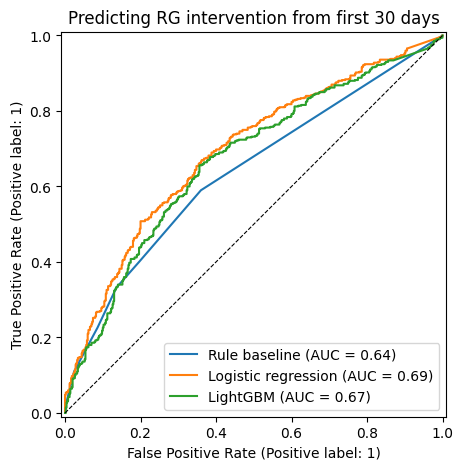

In [8]:
# Cell 8 — Evaluation on the held-out test set
p_logit = logit.predict_proba(X_test)[:, 1]
p_gbm = gbm.predict_proba(X_test)[:, 1]

def flag_top(scores, share=0.2):
    # flag the riskiest 20% of players, like an RG team with limited review capacity
    return (scores >= np.quantile(scores, 1 - share)).astype(int)

rows = []
for name, s in [('Rule baseline', baseline_test + np.random.uniform(0, 1e-6, len(baseline_test))),
                ('Logistic regression', p_logit), ('LightGBM', p_gbm)]:
    flags = flag_top(s)
    rows.append({'model': name, 'AUC': roc_auc_score(y_test, s),
                 'precision@top20%': precision_score(y_test, flags),
                 'recall@top20%': recall_score(y_test, flags)})
results = pd.DataFrame(rows).set_index('model').round(3)
display(results)

fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(y_test, baseline_test, name='Rule baseline', ax=ax)
RocCurveDisplay.from_predictions(y_test, p_logit, name='Logistic regression', ax=ax)
RocCurveDisplay.from_predictions(y_test, p_gbm, name='LightGBM', ax=ax)
ax.plot([0, 1], [0, 1], 'k--', lw=0.8)
ax.set_title(f'Predicting RG intervention from first {WINDOW_DAYS} days')
plt.show()

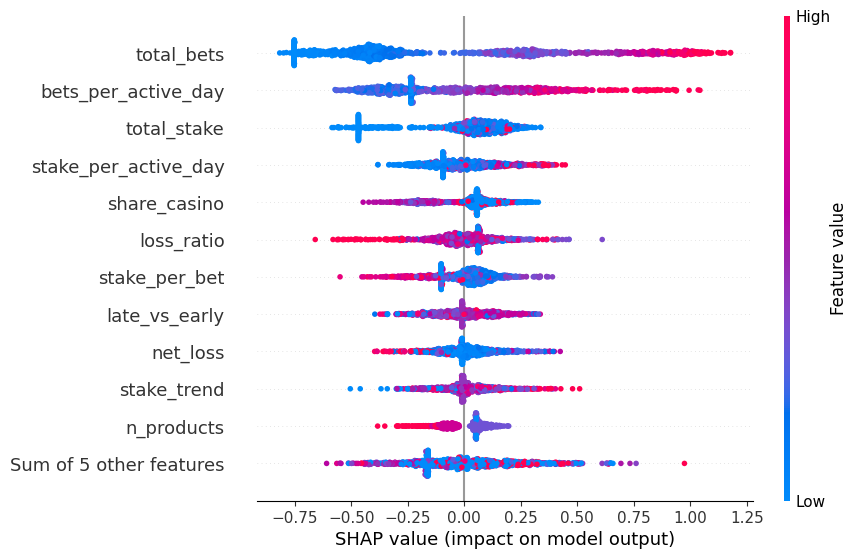

Player 2541: risk score 0.98, actual RG case = 0


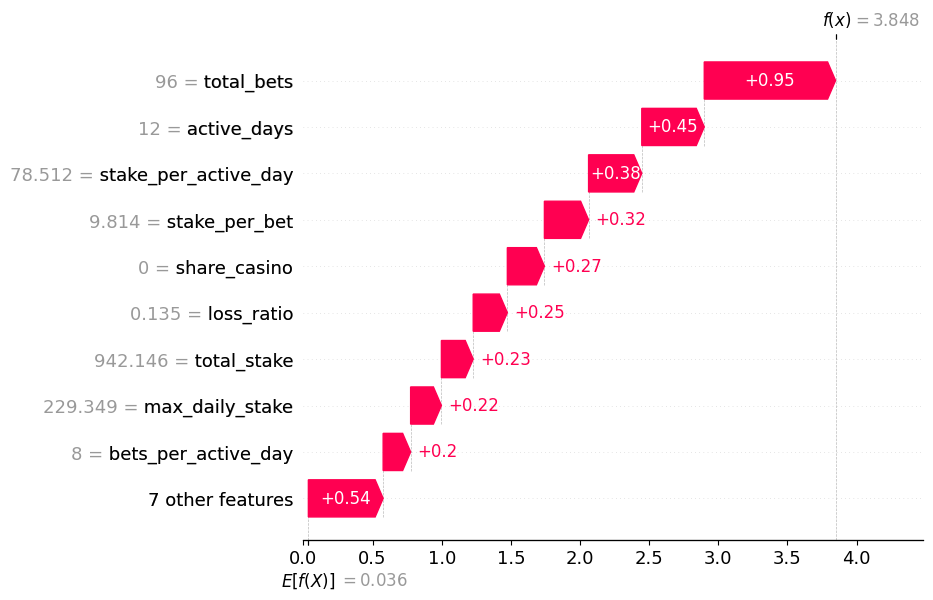

In [9]:
# Cell 9 — Explain the model with SHAP
explainer = shap.TreeExplainer(gbm)
shap_values = explainer(X_test)

# Which behaviours drive risk overall
shap.plots.beeswarm(shap_values, max_display=12)

# Why one specific player was flagged (the highest-scored player in the test set)
top = int(np.argmax(p_gbm))
print(f'Player {data.loc[X_test.index[top], "player"]}: risk score {p_gbm[top]:.2f}, '
      f'actual RG case = {y_test.iloc[top]}')
shap.plots.waterfall(shap_values[top], max_display=10)

In [10]:
# Cell 10 — Summary table for the meeting
importance = (pd.DataFrame({'feature': FEATURES,
                            'mean |SHAP|': np.abs(shap_values.values).mean(axis=0)})
              .sort_values('mean |SHAP|', ascending=False).reset_index(drop=True))
print('Data:', 'REAL bwin cohort' if USE_REAL_DATA else 'SIMULATED stand-in (not meaningful)')
display(results)
display(importance.head(10).round(4))

Data: SIMULATED stand-in (not meaningful)


,AUC,precision@top20%,recall@top20%
model,,,
Rule baseline,0.644,0.725,0.290
Logistic regression,0.693,0.740,0.296
LightGBM,0.669,0.690,0.276


,feature,mean |SHAP|
0,total_bets,0.5033
1,bets_per_active_day,0.2822
2,total_stake,0.1466
3,stake_per_active_day,0.1151
4,share_casino,0.1100
5,loss_ratio,0.1052
6,stake_per_bet,0.0951
7,late_vs_early,0.0936
8,net_loss,0.0859
9,stake_trend,0.0826


In [11]:
# Cell 11 — Export results (tables + charts) as a zip
import os, shutil
from google.colab import files

os.makedirs('results', exist_ok=True)
results.to_csv('results/model_comparison.csv')
importance.to_csv('results/feature_importance.csv', index=False)

fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(y_test, baseline_test, name='Rule baseline', ax=ax)
RocCurveDisplay.from_predictions(y_test, p_logit, name='Logistic regression', ax=ax)
RocCurveDisplay.from_predictions(y_test, p_gbm, name='LightGBM', ax=ax)
ax.plot([0, 1], [0, 1], 'k--', lw=0.8)
ax.set_title(f'Predicting RG intervention from first {WINDOW_DAYS} days')
fig.savefig('results/roc_curves.png', dpi=200, bbox_inches='tight')
plt.close(fig)

shap.plots.beeswarm(shap_values, max_display=12, show=False)
plt.savefig('results/shap_beeswarm.png', dpi=200, bbox_inches='tight'); plt.close()
shap.plots.waterfall(shap_values[top], max_display=10, show=False)
plt.savefig('results/shap_waterfall_top_player.png', dpi=200, bbox_inches='tight'); plt.close()

shutil.make_archive('harm_model_results', 'zip', 'results')
files.download('harm_model_results.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:
# Cell 12 — Save the model and score any player with reasons
import joblib

joblib.dump({'model': gbm, 'features': FEATURES, 'window_days': WINDOW_DAYS,
             'data': 'REAL bwin cohort' if USE_REAL_DATA else 'SIMULATED stand-in'},
            'harm_model.joblib')
print('Saved harm_model.joblib')

def score_player(row: pd.DataFrame, top_n=3):
    """Score one player (a one-row DataFrame with the FEATURES columns).
    Returns the risk score, a risk band, and the behaviours that pushed risk up/down."""
    row = row[FEATURES].astype(float)
    prob = float(gbm.predict_proba(row)[0, 1])
    contrib = pd.Series(explainer(row).values[0], index=FEATURES)
    up = contrib[contrib > 0].sort_values(ascending=False).head(top_n)
    down = contrib[contrib < 0].sort_values().head(top_n)
    band = 'HIGH' if prob >= 0.75 else 'MEDIUM' if prob >= 0.5 else 'LOW'
    return {
        'risk_score': round(prob, 3),
        'risk_band': band,
        'raises_risk': [f'{f} = {row.iloc[0][f]:.2f}  (+{v:.2f})' for f, v in up.items()],
        'lowers_risk': [f'{f} = {row.iloc[0][f]:.2f}  ({v:.2f})' for f, v in down.items()],
        'contributions': contrib,
    }

# Example: the highest-scored player in the test set
example = score_player(X_test.iloc[[top]])
print('Risk score:', example['risk_score'], '·', example['risk_band'])
print('Raises risk:'); print(*example['raises_risk'], sep='\n')
print('Lowers risk:'); print(*example['lowers_risk'], sep='\n')

Saved harm_model.joblib
Risk score: 0.979 · HIGH
Raises risk:
total_bets = 96.00  (+0.95)
active_days = 12.00  (+0.45)
stake_per_active_day = 78.51  (+0.38)
Lowers risk:
late_vs_early = -0.83  (-0.07)
share_sports = 0.00  (-0.01)


In [13]:
# Cell 13 — Interactive demo (Gradio): move the sliders, see the score and the reasons
!pip install -q gradio
import gradio as gr

medians = X_train.median()
def q(col, p=0.99):
    return float(max(X_train[col].quantile(p), 1.0))

share_cols = [c for c in FEATURES if c.startswith('share_')]

def build_row(active_days, total_bets, total_stake, max_daily_stake, net_loss,
              stake_trend, late_vs_early, n_products, share_casino):
    """Turn the slider values into the full 16-feature row the model expects."""
    r = medians.copy()
    active_days = max(active_days, 1)
    r['active_days'] = active_days
    r['total_bets'] = total_bets
    r['total_stake'] = total_stake
    r['max_daily_stake'] = max(max_daily_stake, total_stake / active_days)
    r['net_loss'] = net_loss
    r['stake_per_active_day'] = total_stake / active_days
    r['bets_per_active_day'] = total_bets / active_days
    r['stake_per_bet'] = total_stake / max(total_bets, 1)
    r['loss_ratio'] = float(np.clip(net_loss / max(total_stake, 1e-9), -1, 1))
    r['stake_trend'] = stake_trend
    r['late_vs_early'] = late_vs_early
    r['n_products'] = n_products
    # product mix: casino share from the slider, the rest split evenly across other products
    others = [c for c in share_cols if c != 'share_casino']
    if 'share_casino' in share_cols:
        r['share_casino'] = share_casino
    for c in others:
        r[c] = (1 - share_casino) / len(others) if others else 0
    return pd.DataFrame([r[FEATURES]])

def predict(*slider_values):
    out = score_player(build_row(*slider_values), top_n=4)
    colour = {'HIGH': '🔴', 'MEDIUM': '🟠', 'LOW': '🟢'}[out['risk_band']]
    text = f"## {colour} Risk score: {out['risk_score']:.2f} ({out['risk_band']})\n\n"
    text += '**Raises risk:**\n' + ('\n'.join(f'- {x}' for x in out['raises_risk']) or '- none') + '\n\n'
    text += '**Lowers risk:**\n' + ('\n'.join(f'- {x}' for x in out['lowers_risk']) or '- none')
    c = out['contributions'].reindex(out['contributions'].abs().sort_values().index).tail(8)
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.barh(c.index, c.values, color=['#d62728' if v > 0 else '#1f77b4' for v in c.values])
    ax.axvline(0, color='k', lw=0.8)
    ax.set_xlabel('Contribution to risk (SHAP, log-odds)')
    ax.set_title('Why this score')
    plt.tight_layout()
    return text, fig

with gr.Blocks(title='Gambling Harm Early Detection') as demo:
    gr.Markdown('# Gambling Harm Early Detection\n'
                f'Describe a player\'s first {WINDOW_DAYS} days of betting. The model returns a risk score '
                'and the behaviours behind it.\n\n'
                f'_Model trained on: **{"REAL bwin cohort" if USE_REAL_DATA else "SIMULATED stand-in data (demo only)"}**._')
    with gr.Row():
        with gr.Column():
            inputs = [
                gr.Slider(1, WINDOW_DAYS, value=float(max(medians['active_days'], 1)), step=1, label='Active days'),
                gr.Slider(1, q('total_bets'), value=float(max(medians['total_bets'], 1)), step=1, label='Total bets'),
                gr.Slider(1, q('total_stake'), value=float(max(medians['total_stake'], 1)), label='Total stake'),
                gr.Slider(1, q('max_daily_stake'), value=float(max(medians['max_daily_stake'], 1)), label='Biggest single-day stake'),
                gr.Slider(float(X_train['net_loss'].quantile(0.01)), q('net_loss'), value=float(medians['net_loss']), label='Net loss (stake − wins)'),
                gr.Slider(-0.2, 0.2, value=0.0, step=0.005, label='Stake trend (escalation per day)'),
                gr.Slider(-5, 5, value=0.0, step=0.1, label='Late vs early stake (log change, 2nd half vs 1st)'),
                gr.Slider(1, max(len(share_cols), 1), value=1, step=1, label='Number of products played'),
                gr.Slider(0, 1, value=0.0, step=0.05, label='Share of stake on casino'),
            ]
            btn = gr.Button('Score player', variant='primary')
        with gr.Column():
            result_text = gr.Markdown()
            result_plot = gr.Plot()
    btn.click(predict, inputs=inputs, outputs=[result_text, result_plot])
    gr.Markdown('_Proof of method only. Not a deployed or validated model; any real use needs '
                'retraining on the operator\'s own data, human review of every flag, and a DPIA._')

demo.launch(share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://52c35f851354f63cd8.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## Caveats to state when presenting
- The data is from 2005–2009 bwin players; behaviour and products have changed since.
- The label is "triggered an operator RG intervention", which reflects that operator's own rules, not a clinical diagnosis.
- Cases and controls are balanced 50/50 by design; in a live player base, harm is much rarer, so precision would be lower.
- Data is daily aggregates, so time-of-day markers (night play) aren't available.
- This is a proof of method, not a deployable model.